# 들어가며

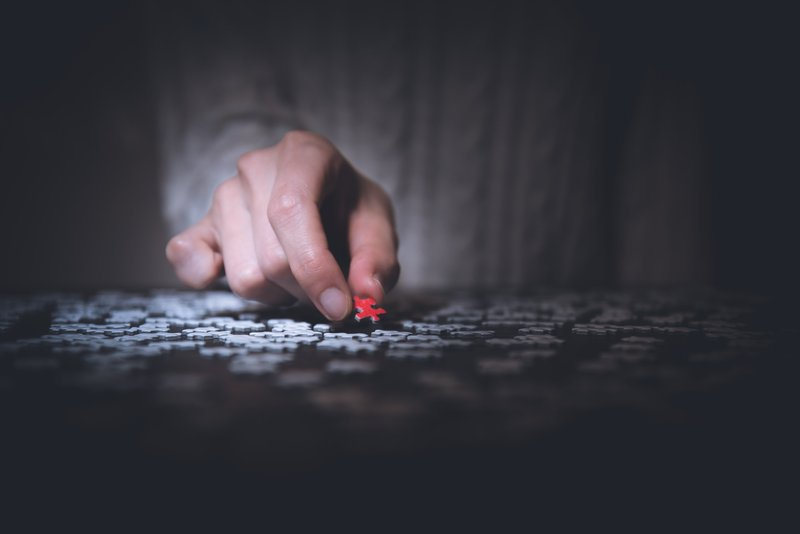

퍼즐 맞추는 것을 즐기시나요? 머리가 복잡해 어딘가에 몰두하고 싶거나, 작은 성취가 고플 땐 퍼즐이 아주 좋답니다. 난이도 별로, 그림 별로 정말 많은 퍼즐이 있고 심지어는 아예 그림이 없는 퍼즐도 있다고 해요 (백야 퍼즐이라고 불린답니다). 필자는 너무 조각 수가 많지 않고, 예쁜 명화를 채워 넣는 퍼즐을 간간이 즐깁니다!

문득 생각하길, 문장을 만드는 것이 마치 퍼즐 맞추기 같더군요. 조각들이 제각기 다른 모양을 가지고 있고, 맞는 위치에 있더라도 그림이 다를 수 있죠. 모양과 그림이 모두 맞아야 비로소 작품이 완성되는 것, 마치 문맥과 문법을 고려하는 것과 꼭 닮았습니다! 대신 우리의 문장 퍼즐은 단 하나의 작품을 목표로 하지 않죠. 올바르게 맞춰진 퍼즐, 그 위의 그림이 어울린다면 그 자체로 작품입니다!

이번 코스에서 우리가 배울 것이 바로 **문장을 조각내는 방법**입니다. 어떤 문장을 일정한 기준을 갖는 단어로 쪼개는 것, 그것은 곧 퍼즐 조각을 나누는 것과 같죠! 지나치게 잘게 쪼개면 넓은 그림을 담을 수 없어 다시 맞추기 어려울 것이고, 너무 크게 쪼갰다간 퍼즐이 너무 쉬워지고 말 겁니다.

이번 코스에선 문장 데이터를 직접 토큰화하며 어떤 방법이 가장 적합한 단어 조각을 만들어 내는지 실습해보도록 하겠습니다.

**[아이스브레이킹] 문장을 조각내는 토큰화?! 토큰화가 뭐였죠?**

A. [ 답변을 적어볼까요! ]

<details>
<summary>💡예시답안 확인하기💡</summary>

문장을 단어나 형태소 등 의미 있는 단위로 쪼개어 처리하는 것을 말합니다.

토큰화(Tokenization)란, 자연어 처리 분야에서 일정한 기준에 따라 문장을 작은 단위로 나누는 작업을 말합니다. 이 작은 단위를 토큰(Token)이라고 합니다.

## 학습 내용
---
2. 데이터 다운로드 및 분석  
 학습 환경을 구성하고 필요한 데이터를 다운로드합니다.
3. 공백 기반 토큰화  
 공백 기반 토큰화를 실습하고 문제점을 확인합니다.
4. 형태소 기반 토큰화  
 KoNLPy, 그중에서도 가장 성능이 준수한 MeCab클래스를 활용해 실습합니다.

## 학습 목표
---
- 학습 환경을 구성하고 필요한 데이터를 다운로드할 수 있습니다.
- 공백 기반 토큰화를 실습하고 문제점을 확인할 수 있습니다.
- 형태소 기반 토큰화를 실습하고 사용할 수 있습니다.

### 준비물
---
이번 코스에서는 KoNLPy, 그중에서도 가장 성능이 준수한 **MeCab클래스**를 활용해 실습하도록 하겠습니다!

**Colab에서 설치하기**
Colab 커널을 열어 다음 명령어를 실행시켜주세요.

```
$ pip install konlpy
$ git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git
$ cd Mecab-ko-for-Google-Colab/
$ bash install_mecab-ko_on_colab_light_220429.sh
```

만일 코드 블럭으로 실행시킨다면 다음과 같습니다.

```python
!pip install konlpy
!git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git
%cd Mecab-ko-for-Google-Colab/
!bash install_mecab-ko_on_colab_light_220429.sh
```

설치가 완료된 후엔 아주 간편하게 `import` 하여 형태소 분석기를 사용하실 수 있습니다. 단, 설치 후에는 꼭 세션을 재시작해주세요.

In [60]:
!pip install konlpy
!git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git
%cd Mecab-ko-for-Google-Colab/
!bash install_mecab-ko_on_colab_light_220429.sh

Cloning into 'Mecab-ko-for-Google-Colab'...
remote: Enumerating objects: 138, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 138 (delta 26), reused 22 (delta 8), pack-reused 91 (from 1)
Receiving objects: 100% (138/138), 1.72 MiB | 20.91 MiB/s, done.
Resolving deltas: 100% (65/65), done.
/content/Mecab-ko-for-Google-Colab/Mecab-ko-for-Google-Colab/Mecab-ko-for-Google-Colab
Installing konlpy.....
Done
Installing mecab-0.996-ko-0.9.2.tar.gz.....
from https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
--2026-11-04 03:54:03--  https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
Resolving bitbucket.org (bitbucket.org)... 104.192.142.26, 104.192.142.25, 104.192.142.24, ...
Connecting to bitbucket.org (bitbucket.org)|104.192.142.26|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-04 03:54:03 ERROR 404: Not Found.

Done
Unpacking mecab-0.996-ko-

In [61]:
from konlpy.tag import Mecab

mecab = Mecab()
print(mecab.morphs('자연어처리가너무재밌어서밥먹는것도가끔까먹어요'))

['자연어', '처리', '가', '너무', '재밌', '어서', '밥', '먹', '는', '것', '도', '가끔', '까먹', '어요']


# 데이터 다운로드 및 분석
먼저 프로젝트에 사용될 라이브러리를 `import` 합니다.

In [62]:
import os

import matplotlib.pyplot as plt
import torch
import numpy as np

%matplotlib inline

그럼 학습환경을 구성하고 데이터를 다운받아 보겠습니다.
cloud shell에서 다음 명령어들을 순서대로 입력해주세요.

```
$ wget https://github.com/jungyeul/korean-parallel-corpora/raw/master/korean-english-news-v1/korean-english-park.train.tar.gz
$ tar -xzvf korean-english-park.train.tar.gz
```



In [63]:
!wget https://github.com/jungyeul/korean-parallel-corpora/raw/master/korean-english-news-v1/korean-english-park.train.tar.gz
!tar -xzvf korean-english-park.train.tar.gz

--2026-11-04 03:54:07--  https://github.com/jungyeul/korean-parallel-corpora/raw/master/korean-english-news-v1/korean-english-park.train.tar.gz
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/jungyeul/korean-parallel-corpora/master/korean-english-news-v1/korean-english-park.train.tar.gz [following]
--2026-11-04 03:54:08--  https://raw.githubusercontent.com/jungyeul/korean-parallel-corpora/master/korean-english-news-v1/korean-english-park.train.tar.gz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8718893 (8.3M) [application/octet-stream]
Saving to: ‘korean-english-park.train.tar.gz’

korean-eng

In [64]:
import os
path_to_file = "korean-english-park.train.ko"

with open(path_to_file, "r") as f:
    raw = f.read().splitlines()

print("Data Size:", len(raw))

print("Example:")
for sen in raw[0:100][::20]: print(">>", sen)

Data Size: 94123
Example:
>> 개인용 컴퓨터 사용의 상당 부분은 "이것보다 뛰어날 수 있느냐?"
>> 북한의 핵무기 계획을 포기하도록 하려는 압력이 거세지고 있는 가운데, 일본과 북한의 외교관들이 외교 관계를 정상화하려는 회담을 재개했다.
>> "경호 로보트가 침입자나 화재를 탐지하기 위해서 개인적으로, 그리고 전문적으로 사용되고 있습니다."
>> 수자원부 당국은 논란이 되고 있고, 막대한 비용이 드는 이 사업에 대해 내년에 건설을 시작할 계획이다.
>> 또한 근력 운동은 활발하게 걷는 것이나 최소한 20분 동안 뛰는 것과 같은 유산소 활동에서 얻는 운동 효과를 심장과 폐에 주지 않기 때문에, 연구학자들은 근력 운동이 심장에 큰 영향을 미치는지 여부에 대해 논쟁을 해왔다.


내려받은 데이터는 한국어의 형태소 분석과 품사 태깅, 기계 번역 연구를 위해 공개된 데이터입니다. 이번에 사용할 데이터는 한국어-영어 병렬을 이루는 말뭉치 중 한국어 부분으로, 전체 병렬 말뭉치는 후에 번역기를 만들며 사용할 예정입니다!

혹시 다른 종류의 데이터가 궁금하시다면 아래 Github를 방문해보세요!

- [jungyeul/korean-parallel-corpora](https://github.com/jungyeul/korean-parallel-corpora)

자, 데이터가 우리 손으로 들어왔으니 씹고 뜯고 맛볼 차례입니다! 멋진 시각화를 동반한 통계적 분석...까지는 하지 않고요. 최소한의 분석으로 데이터가 얼마나 있고, 어떻게 생겼는지 정도를 직접 확인해 봅시다.

문장은 위에서 확인한 것처럼 `94123`개가 포함되어 있습니다. 우리는 각 문장이 어느 정도의 길이를 가지는지 확인해보겠습니다! 이 과정을 거치면 지나치게 긴 데이터를 삭제하거나 (*연산량을 감소시켜 학습 속도가 빨라집니다!*) 지나치게 짧은 데이터를 검증 (*무조건 필요가 없지는 않습니다, `단어 ↔ 단어` 라면 번역을 학습할 수 있겠죠!*) 할 수 있습니다. 즉, **데이터를 얼마나 사용할지 타협점을 정의**할 수 있습니다.

아래 소스는 문장의 최단 길이, 최장 길이, 평균 길이를 구한 후 문장 길이 분포를 막대그래프로 표현해 주는 소스입니다. raw 변수는 앞서 다운로드받은 데이터가 담긴 변수입니다!

문장의 최단 길이: 1
문장의 최장 길이: 377
문장의 평균 길이: 60


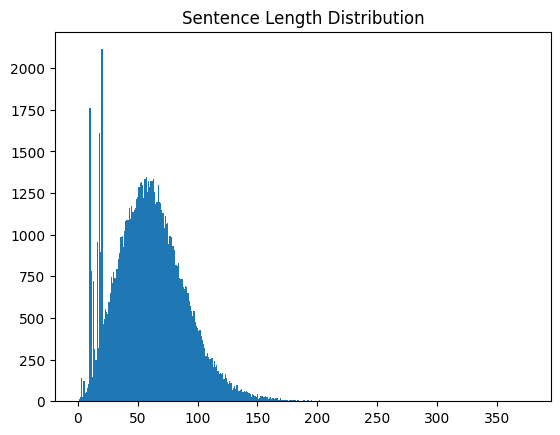

In [65]:
min_len = 999
max_len = 0
sum_len = 0

for sen in raw:
    length = len(sen)
    if min_len > length: min_len = length
    if max_len < length: max_len = length
    sum_len += length

print("문장의 최단 길이:", min_len)
print("문장의 최장 길이:", max_len)
print("문장의 평균 길이:", sum_len // len(raw))

sentence_length = np.zeros((max_len), dtype=int)

for sen in raw:
    sentence_length[len(sen)-1] += 1

plt.bar(range(max_len), sentence_length, width=1.0)
plt.title("Sentence Length Distribution")
plt.show()

최단 길이 1, 최장 길이 377... 그리고 제법 그럴듯한 막대그래프가 나왔습니다만, 이 결과를 확인하고 드는 생각은 아래와 크게 다르지 않으실 거예요..!

*1) 길이 1 짜리 문장은 도대체 어떻게 생겨먹었지?*

*2) 앞에 치솟는 임의의 구간은 뭐지? 유의미한 데이터가 담겨있는 부분인가?*

*3) 어디서부터 어디까지 잘라서 쓰지?*

궁금증을 하나하나 해결해 봅시다! 대체 길이가 1인 문장은 뭘까요?

In [66]:
def check_sentence_with_length(raw, length):
    count = 0

    for sen in raw:
        if len(sen) == length:
            print(sen)
            count += 1
            if count > 100: return

check_sentence_with_length(raw, 1)

’


오잉? 하마터면 완전 노이즈인 데이터를 그대로 사용할 뻔했습니다! 왠지 길이별로 확인할 일이 많을 것 같아 함수를 미리 정의해두었는데, 이를 이용해 확인이 필요해 보이는 문장은 모두 확인해보죠.

In [67]:
for idx, _sum in enumerate(sentence_length):
    # 문장의 수가 1500을 초과하는 문장 길이를 추출합니다.
    if _sum > 1500:
        print("Outlier Index:", idx+1)

Outlier Index: 11
Outlier Index: 19
Outlier Index: 21


위에서 찾은 outlier index 중 하나인, 길이가 11인 문장들은 어떤 것들이 있는지 확인해봅시다.

In [68]:
check_sentence_with_length(raw, 11)

라고 조던이 말했다.
- 모르고 있습니다.
- 네, 보이는군요.
디즈니사만이 아니다.
큰 파티는 아니지요.
의자는 비어 있었다.
이 일은 계속됩니다.
나는 크게 실망했다.
그 이유는 간단하다.
이력서와 자기 소개서
시대가 변하고 있다.
는 돌발질문을 했다.
9. 몇 분간의 명상
하와이, 빅 아일랜드
키스를 잘 하는 방법
키스를 잘 하는 방법
스피어스가 뚱뚱한가?
산 위를 나는 느낌.
세 시간쯤 걸었을까?
(아직 읽고있습니까?
처음에는 장난이었다.
우리는 운이 좋았다.
아기가 숨을 멈출 때
건물 전체 무너져내려
그녀의 아름다운 눈.
대답은 다음과 같다.
"사과할 것이 없다.
폭탄테러가 공포 유발
그는 "잘 모르겠다.
그는 "잘 모르겠다.
그는 "잘 모르겠다.
그는 "잘 모르겠다.
그는 "잘 모르겠다.
그는 "잘 모르겠다.
그는 "잘 모르겠다.
그는 "잘 모르겠다.
그는 "잘 모르겠다.
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1200원대로…
더 내려야 하는 이유
케냐 야생동물 고아원
경유 1

이런... 심지어 중복에 대한 처리도 제대로 하지 않았었네요. 중복 제거는 Python의 기본 자료형 `set`을 활용할 겁니다. `set`은 집합을 정의하는 자료형인데, 중복을 허용하지 않아 **변환 과정에서 자동으로 중복된 요소를 제거**해 주거든요! 대신 `list`의 순서가 뒤죽박죽될 수 있으니, 만약 번역 데이터처럼 쌍을 이뤄야 하는 경우라면 주의해서 사용하셔야 합니다!

중복을 제거한 후, 앞에서 분포를 확인한 소스를 다시 실행시켜 보겠습니다!

Data Size: 77591
문장의 최단 길이: 1
문장의 최장 길이: 377
문장의 평균 길이: 64


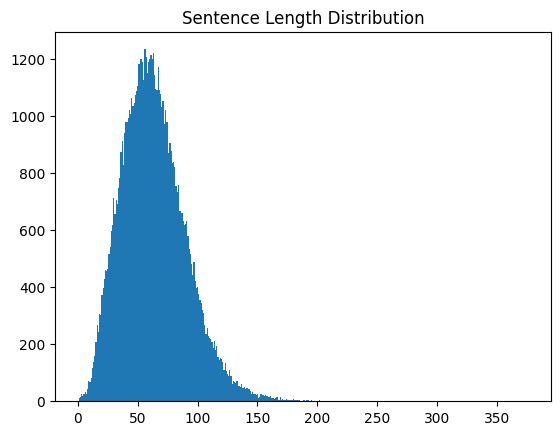

In [69]:
min_len = 999
max_len = 0
sum_len = 0

cleaned_corpus = list(set(raw))  # set를 사용해서 중복을 제거합니다.
print("Data Size:", len(cleaned_corpus))

for sen in cleaned_corpus:
    length = len(sen)
    if min_len > length: min_len = length
    if max_len < length: max_len = length
    sum_len += length

print("문장의 최단 길이:", min_len)
print("문장의 최장 길이:", max_len)
print("문장의 평균 길이:", sum_len // len(cleaned_corpus))

sentence_length = np.zeros((max_len), dtype=int)

for sen in cleaned_corpus:   # 중복이 제거된 코퍼스 기준
    sentence_length[len(sen)-1] += 1

plt.bar(range(max_len), sentence_length, width=1.0)
plt.title("Sentence Length Distribution")
plt.show()

이제서야 깔끔한 데이터를 얻은 느낌이 드네요. 데이터의 개수도 `17000`개 가량 줄어 `77591`개가 되었습니다.

마지막으로 '모든 데이터를 다 사용할 것이냐' 가 문제인데, 후에 미니 배치를 만들 것을 생각하면 모든 데이터를 다 사용하는 것은 연산 측면에서 비효율적입니다. 미니 배치 특성상 각 데이터의 크기가 모두 동일해야 하기 때문에 **가장 긴 데이터를 기준으로 Padding 처리**를 해야 합니다. 위의 데이터에서 만약 길이가 100인 문장까지만 사용한다면 데이터는 `[ (77591 - 길이 100 초과 문장 수) x 100 ]` 의 형태를 갖겠지만 모두 사용할 경우 `[ 77591 x 377 ]` 로 **전자보다 최소 3.7배 큰 메모리를 차지**합니다. 학습 시간도 그만큼 더 오래 걸리고요.

길이별로 정렬하여 미니 배치를 구성해 Padding을 최소화하는 방법도 있지만 이는 데이터를 섞는 데 편향성이 생길 수 있으므로 지양해야 합니다. 여기서는 길이 150 이상의 데이터를 제거하고 사용하도록 할게요!

그리고 앞서 확인한 것처럼 너무 짧은 데이터는 오히려 노이즈로 작용할 수 있습니다. 따라서 길이가 10 미만인 데이터도 제거하도록 하죠! 최종 데이터 분포도 함께 확인해봅시다.

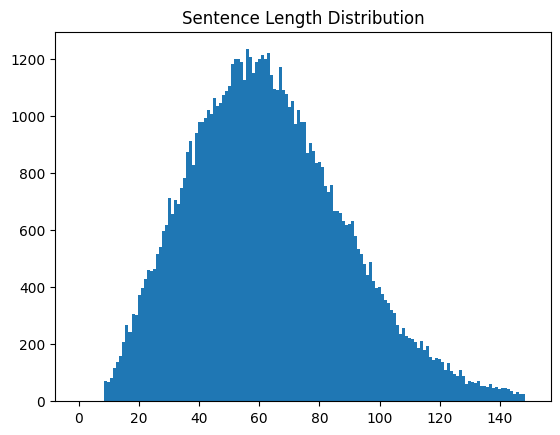

In [70]:
max_len = 150
min_len = 10

# 길이 조건에 맞는 문장만 선택합니다.
filtered_corpus = [s for s in cleaned_corpus if (len(s) < max_len) & (len(s) >= min_len)]

# 분포도를 다시 그려봅니다.
sentence_length = np.zeros((max_len), dtype=int)

for sen in filtered_corpus:
    sentence_length[len(sen)-1] += 1

plt.bar(range(max_len), sentence_length, width=1.0)
plt.title("Sentence Length Distribution")
plt.show()

이제 정말 사용할 준비가 된 것 같죠? 본격적인 작업을 시작해봅시다!

# 공백 기반 토큰화
배운 순서대로, 먼저 공백 기반 토큰화를 진행해 봅시다!

**이전 스텝에서 얻은 정제된 데이터 `filtered_corpus`를 공백 기반으로 토큰화하여 리스트 `split_corpus`에 저장한 후, 아래 `tokenize()` 함수를 사용해 단어 사전과 Tensor 데이터를 얻으세요! 그리고 단어 사전의 크기를 확인하세요!**

In [71]:
import torch
from torch.nn.utils.rnn import pad_sequence

class Tokenizer:
    def __init__(self, filters=''):
        self.word_index = {}
        self.index_word = {}
        self.filters = filters

    def fit_on_texts(self, corpus):
        # 각 문장을 토큰화하여 단어 사전을 생성 (인덱스는 1부터 시작)
        for sentence in corpus:
            tokens = sentence.split() if isinstance(sentence, str) else sentence
            for token in tokens:
                if token not in self.word_index:
                    self.word_index[token] = len(self.word_index) + 1
        # 역방향 사전 생성
        self.index_word = {idx: word for word, idx in self.word_index.items()}

    def texts_to_sequences(self, corpus):
        sequences = []
        for sentence in corpus:
            tokens = sentence.split() if isinstance(sentence, str) else sentence
            # 존재하지 않는 단어는 0으로 처리
            seq = [self.word_index.get(token, 0) for token in tokens]
            sequences.append(torch.tensor(seq, dtype=torch.long))
        return sequences

    def sequences_to_texts(self, sequences):
        texts = []
        for seq in sequences:
            # tensor인 경우 리스트로 변환
            if isinstance(seq, torch.Tensor):
                seq = seq.tolist()
            # 패딩 토큰(0)은 제외하고 디코딩
            tokens = [self.index_word.get(idx, "") for idx in seq if idx != 0]
            texts.append(tokens)
        return texts

In [72]:
def tokenize(corpus):
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(corpus)
    sequences = tokenizer.texts_to_sequences(corpus)
    # padding 토큰은 0
    tensor = pad_sequence(sequences, batch_first=True, padding_value=0)
    return tensor, tokenizer

In [73]:
# 정제된 데이터 filtered_corpus를 공백 기반으로 토큰화하여 저장하는 코드를 직접 작성해 보세요.
split_corpus = []

for kor in filtered_corpus:
    split_corpus.append(kor.split())

In [74]:
len(split_corpus)

76908

▶️ 세모 모양 이모지를 클릭하시면, 상세 내용을 확인하실 수 있습니다.

<details>
<summary>코드 확인</summary>

```
split_corpus = []

for kor in filtered_corpus:
    split_corpus.append(kor.split())
```

</details>

정답을 확인해 보셨나요? 이제 공백 기반 토큰화를 진행한 후, 단어 사전의 길이를 확인해봅시다.

In [75]:
split_tensor, split_tokenizer = tokenize(split_corpus)

print("Split Vocab Size:", len(split_tokenizer.index_word))

Split Vocab Size: 238305


아래의 코드로 생성된 단어 사전을 확인해 볼 수 있습니다.

In [76]:
for idx, word in enumerate(split_tokenizer.word_index):
    print(idx, ":", word)

    if idx > 10: break

0 : 하지만,
1 : 최근의
2 : 여론
3 : 조사는
4 : 이
5 : 후보의
6 : 지지율이
7 : 더
8 : 이상
9 : 줄어들지
10 : 않고
11 : 있음을


동사로 이루어진 단어를 살피면 **공백 기반 토큰화의 문제점**을 확인할 수 있습니다. 1번 단어인 `밝혔다.` 는 `밝히다` , `밝다` 등과 유사한 의미를 지니고 있음에도 전혀 다른 단어로 분류되겠죠? 이 때문에 공백 기반 토큰화는 **불필요하게 큰 단어 사전을 가지게 되며 이는 연산량 증가**로 이어집니다.

만일 `밝 + 혔다` **라고 토큰화했다면** 어땠을까요? `밝 + 히다`, `밝 + 다` 같은 구절이 등장했을 때, 공통된 어절인 `밝` 은 하나로 묶여 **학습 중에 의미를 파악하기가 수월**해지겠죠? 동시에 단어 사전도 효율적으로 축소될 것입니다. 이를 위해 **형태소 분석기**가 존재합니다!

# 형태소 기반 토큰화
한국어 형태소 분석기는 대표적으로 *Khaiii*와 *KoNLPy*가 사용됩니다. 이번 코스에서는 *KoNLPy*, 그중에서도 가장 성능이 준수한 **MeCab클래스를 활용**해 실습하도록 하겠습니다!

앞서 작성했던 코드를 활용해 MeCab 기반으로 생성된 단어 사전과 Tensor 데이터를 얻어 봅시다!

In [77]:
# 위에서 사용한 코드를 활용해 MeCab 단어 사전을 만들어보세요.
# Hint : mecab.morphs()를 사용해서 형태소분석을 합니다.
def mecab_split(sentence):
    return mecab.morphs(sentence)

mecab_corpus = []

for kor in filtered_corpus:
    mecab_corpus.append(mecab_split(kor))

<details>
<summary> 코드 확인 </summary>

```
def mecab_split(sentence):
    return mecab.morphs(sentence)

mecab_corpus = []

for kor in filtered_corpus:
    mecab_corpus.append(mecab_split(kor))
```

</details>

정답을 확인해 보셨나요? 이제 형태소 기반 토큰화를 진행한 후, 단어 사전의 길이를 확인해 봅시다.

In [78]:
mecab_tensor, mecab_tokenizer = tokenize(mecab_corpus)

print("MeCab Vocab Size:", len(mecab_tokenizer.index_word))

MeCab Vocab Size: 53642


앞서 실습했던 공백 기반 단어 사전에 비해 단어 수가 현저히 줄어든 것을 확인하셨을 겁니다. 이는 곧 연산량의 감소로 이어져 더 빠른 학습을 가능케 하고, 심지어 모델이 튜닝해야 하는 매개변수(Parameter) 수가 줄어들어 학습도 더 잘 된답니다! 적어도 한국어를 처리할 때는 **공백 기반 토큰화를 절대 지양**하셔야 해요!

자주 사용되는 *SentencePiece*같은 Subword 기반 토큰화보다 형태소 분석기가 좋은 성능을 내는 사례들이 종종 있는데요, ETRI에서 발표한 한국어 BERT 모델인 **KorBERT**가 대표적인 사례 중 하나입니다. 아래 웹페이지를 방문하면 모델의 자세한 구조뿐 아니라 KorBERT 모델을 5가지 자연어 처리 태스크를 기준으로 평가했던 흥미로운 결과까지 살펴보실 수 있습니다!

- [공공 인공지능 오픈 API·DATA 서비스 포털](https://aiopen.etri.re.kr/bertModel)

자연어 처리에서 토크나이저가 성능에 미치는 영향도가 크다는 것은 주지의 사실입니다만, 위 링크에서 발표된 평가 결과를 살펴볼 때 몇 가지 생각해 볼 만한 지점이 있습니다.

아래 질문들에 대해 스스로 생각해 보고 본인의 생각을 정리해서 답변해 보시기 바랍니다. 사실 정답이 있는 문제는 아니기 때문입니다.

**Q. 구글의 Word Piece 기반 한국어 언어모델이 엑소브레인의 Word Piece 기반 한국어 언어모델보다 전체적으로 성능이 크게 떨어지는 것은 어떤 의미일까요? 여기서 유의해야 할 것은 언어모델(BERT)을 훈련시킨 원리는 동일하며, 토크나이저가 구성된 원리도 Word Piece 기반으로 동일하다는 점입니다.**

A. [ 답변을 적어볼까요! ]

<details>
<summary>💡예시답안 확인하기💡</summary>

구글에서 배포한 BERT 모델은 한국어 전용 코퍼스를 바탕으로 훈련된 것이 아니라 Multilingual 코퍼스를 바탕으로 훈련된 것이며, Word Piece 모델 안에 포함된 subword 안에도 한국어가 아닌 여러 언어의 것이 섞여 있어서 한국어 자연어처리 태스크에 특화된 모델이 아닙니다. (상세한 내용은 https://github.com/google-research/bert 참조)

엑소브레인의 것은 한국어 코퍼스에 특화된 형태로 언어모델과 토크나이저가 훈련된 것이므로 엑소브레인과 구글의 BERT 모델의 한국어 테스크 성능 차이는 한국어에 특화된 언어 모델을 구축했을 때 기대할 수 있는 성능 향상치로 해석할 수 있습니다.

**Q. 엑소브레인의 BERT에 두 가지 버전이 있는데, 이 중 한국어 전용 형태소분석기 토크나이저를 사용한 버전이 WordPiece 모델 토크나이저를 사용한 버전보다 대체로 성능이 좋다는 것의 시사점은 무엇일까요?**

A. [ 답변을 적어볼까요! ]

<details>
<summary>💡예시답안 확인하기💡</summary>

WordPiece 모델은 해당 언어의 문법적 및 의미적 사전정보가 반영되지 않은 채 순수하게 통계적인 빈도 기반으로 자주 사용되는 반복 패턴을 사전으로 등재해 놓은 것에 불과합니다. 그에 비해 정확한 한국어 문법과 의미정보를 바탕으로 개발된 형태소분석기가 정확하게 동작한다면 현재까지 가장 성능이 좋다고 알려진 Subword 기반의 토크나이저보다 더 성능이 좋을 수 있음을 보여 줍니다.

**Q. 정교한 형태소분석기를 활용한 모델의 성능이 더 좋을 수 있음에도 불구하고 현장에서 SentencePiece 같은 Subword 기반 토크나이저가 더욱 각광받는 이유는 무엇일까요?**

A. [ 답변을 적어볼까요! ]

<details>
<summary>💡예시답안 확인하기💡</summary>

언어는 지속적으로 변합니다. 정교한 형태소분석기의 성능을 유지하기 위해서는 지속적인 데이터관리와 유지보수 작업이 필요합니다.

그에 비해 SentencePiece 모델은 코퍼스데이터로부터 쉽게 추출해서 생성 가능하며, Subword 기반이기 때문에 새롭게 생성되는 단어에 대한 OOV(Out-of-Vocabulary) 문제에 대해서도 robust하게 대처할 수 있는 장점이 있습니다. 그리고 언어에 중립적이기 때문에 여러 언어가 섞여 나오는 텍스트를 처리하는 데에도 능합니다.

무엇보다도, 특정 언어에 대한 부가지식이 없이도 엔지니어가 그 언어에 대한 작업을 손쉽게 진행할 수 있도록 해준다는 점과 그 언어에 특화된 토크나이저의 성능에 뒤지지 않거나 대체로 능가하는 성능을 보여주기 때문입니다.

지금까지 문장을 Tensor로 Encoding하는 과정을 배웠는데요. \
후에 모델이 생성한 Tensor를 문장으로 Decoding하는 과정도 필요하겠죠?

- `tokenizer.sequences_to_texts()` 함수를 사용하여 Decoding
- `tokenizer.index_word` 를 사용하여 Decoding

두 가지 방법으로 `mecab_tensor[100]` 을 원문으로 되돌려 보세요!  
(여기서 띄어쓰기는 고려하지 않습니다!)

In [79]:
# Case 1 : tokenizer.sequences_to_texts()

texts = mecab_tokenizer.sequences_to_texts([mecab_tensor[100]])
print(texts[0])

['매케인', '의', '변호사', '인', '로버트', '베넷', '도', '기사', '내용', '을', '비판', '했', '다', '.']


<details>
<summary>코드 확인</summary>

```
# Case 1
texts = mecab_tokenizer.sequences_to_texts([mecab_tensor[100]])
print(texts[0])
```



In [80]:
# Case 2 : tokenizer.index_word

sentence = ""

for w in mecab_tensor[100]:
    w = int(w)
    if w == 0: continue
    sentence += mecab_tokenizer.index_word[w] + " "

print(sentence)

매케인 의 변호사 인 로버트 베넷 도 기사 내용 을 비판 했 다 . 


<details>
<summary>코드 확인</summary>

```
# Case 2
sentence = ""

for w in mecab_tensor[100]:
    if w == 0: continue
    sentence += mecab_tokenizer.index_word[w] + " "

print(sentence)
```



# 프로젝트: SentencePiece 사용하기

## 라이브러리 버전을 확인해 봅니다
---
사용할 라이브러리 버전을 둘러봅시다.

In [81]:
import torch
from torch.nn.utils.rnn import pad_sequence
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import konlpy

print(torch.__version__)
print(np.__version__)
print(matplotlib.__version__)
print(konlpy.__version__)

2.11.0+cu130
2.4.6
3.10.0
0.6.0


## Step 1. SentencePiece 설치하기
---
SentencePiece는 Google에서 제공하는 오픈소스 기반 Sentence Tokenizer/Detokenizer 로서, BPE와 unigram 2가지 subword 토크나이징 모델 중 하나를 선택해서 사용할 수 있도록 패키징한 것입니다. 아래 링크의 페이지에서 상세한 내용을 파악할 수 있습니다.

- [google/sentencepiece](https://github.com/google/sentencepiece)

위 페이지의 서두에서도 언급하고 있듯, SentencePiece는 딥러닝 자연어처리 모델의 앞부분에 사용할 목적으로 최적화되어 있는데, 최근 pretrained model들이 거의 대부분 SentencePiece를 tokenizer로 채용하면서 사실상 표준의 역할을 하고 있습니다.

다음과 같이 설치를 진행합니다. SentencePiece는 python에서 쓰라고 만들어진 라이브러리는 아니지만 편리한 파이썬 wrapper를 아래와 같이 제공하고 있습니다.

```
$ pip install sentencepiece
```

In [82]:
!pip install sentencepiece

## Step 2. SentencePiece 모델 학습
---
앞서 배운 `tokenize()` 함수를 기억하나요? 다시 한번 상기시켜드릴게요!

```python
class Tokenizer:
    def __init__(self, filters=''):
        self.word_index = {}
        self.index_word = {}
        self.filters = filters

    def fit_on_texts(self, corpus):
        for sentence in corpus:
            tokens = sentence.split() if isinstance(sentence, str) else sentence
            for token in tokens:
                if token not in self.word_index:
                    self.word_index[token] = len(self.word_index) + 1
        self.index_word = {idx: word for word, idx in self.word_index.items()}

    def texts_to_sequences(self, corpus):
        sequences = []
        for sentence in corpus:
            tokens = sentence.split() if isinstance(sentence, str) else sentence
            seq = [self.word_index.get(token, 0) for token in tokens]
            sequences.append(torch.tensor(seq, dtype=torch.long))
        return sequences

    def sequences_to_texts(self, sequences):
        texts = []
        for seq in sequences:
            if isinstance(seq, torch.Tensor):
                seq = seq.tolist()
            tokens = [self.index_word.get(idx, "") for idx in seq if idx != 0]
            texts.append(tokens)
        return texts

def tokenize(corpus):
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(corpus)
    sequences = tokenizer.texts_to_sequences(corpus)
    tensor = pad_sequence(sequences, batch_first=True, padding_value=0)
    return tensor, tokenizer
```

위와 같이 `Tokenizer`에 corpus를 주고 `tokenizer.fit_on_texts(corpus)`을 하면 토크나이저 내부적으로 단어사전과 토크나이저 기능을 corpus에 맞춤형으로 자동 생성해 주는 것입니다.

그럼 이를 위해서 SentencePiece 모델을 학습하는 과정을 거쳐야 합니다.

```python
import sentencepiece as spm
import os
temp_file = 'korean-english-park.train.ko.temp'

vocab_size = 8000

with open(temp_file, 'w') as f:
    for row in filtered_corpus:   # 이전에 나왔던 정제했던 corpus를 활용해서 진행해야 합니다.
        f.write(str(row) + '\n')

spm.SentencePieceTrainer.Train(
    '--input={} --model_prefix=korean_spm --vocab_size={}'.format(temp_file, vocab_size)    
)
#위 Train에서  --model_type = unigram이 디폴트 적용되어 있습니다. --model_type = bpe로 옵션을 주어 변경할 수 있습니다.

!ls -l korean_spm*
```

위 코드를 실행하면 정상적으로 SentencePiece 모델 학습이 완료된 후 `korean_spm.model` 파일과 `korean_spm.vocab` vocabulary 파일이 생성되었음을 확인할 수 있습니다.

그럼 이렇게 학습된 SentencePiece 모델을 어떻게 활용하는지 살펴보겠습니다.

```python
s = spm.SentencePieceProcessor()
s.Load('korean_spm.model')

# SentencePiece를 활용한 sentence -> encoding
tokensIDs = s.EncodeAsIds('아버지가방에들어가신다.')
print(tokensIDs)

# SentencePiece를 활용한 sentence -> encoded pieces
print(s.SampleEncodeAsPieces('아버지가방에들어가신다.',-1, 0.1))

# SentencePiece를 활용한 encoding -> sentence 복원
print(s.DecodeIds(tokensIDs))
```

어떻습니까? SentencePiece의 토크나이징 실력이 괜찮은 것 같습니다.

In [83]:
import sentencepiece as spm
import os
temp_file = 'korean-english-park.train.ko.temp'

vocab_size = 8000

with open(temp_file, 'w') as f:
    for row in filtered_corpus:   # 이전에 나왔던 정제했던 corpus를 활용해서 진행해야 합니다.
        f.write(str(row) + '\n')

spm.SentencePieceTrainer.Train(
    '--input={} --model_prefix=korean_spm --vocab_size={}'.format(temp_file, vocab_size)
)
# 위 Train에서  --model_type = unigram이 디폴트 적용되어 있습니다. --model_type = bpe로 옵션을 주어 변경할 수 있습니다.

!ls -l korean_spm*

-rw-r--r-- 1 root root 380936 Nov  4 03:55 korean_spm.model
-rw-r--r-- 1 root root 147830 Nov  4 03:55 korean_spm.vocab


In [84]:
s = spm.SentencePieceProcessor()
s.Load('korean_spm.model')

# SentencePiece를 활용한 sentence -> encoding
tokensIDs = s.EncodeAsIds('아버지가방에들어가신다.')
print(tokensIDs)

# SentencePiece를 활용한 sentence -> encoded pieces
print(s.SampleEncodeAsPieces('아버지가방에들어가신다.',-1, 0.1))

# SentencePiece를 활용한 encoding -> sentence 복원
print(s.DecodeIds(tokensIDs))

[1202, 10, 318, 6, 3748, 10, 287, 31, 4]
['▁', '아버지', '가', '방', '에', '들', '어', '가', '신', '다', '.']
아버지가방에들어가신다.


## Step 3. Tokenizer 함수 작성
---
우리는 위에서 훈련시킨 SentencePiece를 활용하여 위 함수와 유사한 기능을 하는 `sp_tokenize()` 함수를 정의할 겁니다. 하지만 SentencePiece가 동작하는 방식이 단순 토큰화와는 달라 완전히 동일하게는 정의하기 어렵습니다. 그러니 아래 조건을 만족하는 함수를 정의하도록 하습니다.

> 1. 매개변수로 토큰화된 문장의 `list`를 전달하는 대신 온전한 문장의 `list` 를 전달합니다.
>
> 2. 생성된 vocab 파일을 읽어와 `{ <word> : <idx> }` 형태를 가지는 `word_index` 사전과 `{ <idx> : <word>}` 형태를 가지는 `index_word` 사전을 생성하고 함께 반환합니다.
>
> 3. 리턴값인 `tensor` 는 앞의 함수와 동일하게 토큰화한 후 Encoding된 문장입니다. 바로 학습에 사용할 수 있게 Padding은 당연히 해야겠죠?

```python
def sp_tokenize(s, corpus):

    tensor = []

    for sen in corpus:
        tensor.append(s.EncodeAsIds(sen))

    with open("./korean_spm.vocab", 'r') as f:
        vocab = f.readlines()

    word_index = {}
    index_word = {}

    for idx, line in enumerate(vocab):
        word = line.split("\t")[0]

        word_index.update({word:idx})
        index_word.update({idx:word})

    tensor = pad_sequence(tensor, batch_first=True, padding_value=0)

    return tensor, word_index, index_word
```

In [85]:

import torch
from torch.nn.utils.rnn import pad_sequence

def sp_tokenize(s, corpus):

    tensor = []

    for sen in corpus:
        ids = s.EncodeAsIds(sen)
        tensor.append(torch.tensor(ids, dtype=torch.long))

    with open("./korean_spm.vocab", "r", encoding="utf-8") as f:
        vocab = f.readlines()

    word_index = {}
    index_word = {}

    for idx, line in enumerate(vocab):
        word = line.split("\t")[0]

        word_index[word] = idx
        index_word[idx] = word

    tensor = pad_sequence(
        tensor,
        batch_first=True,
        padding_value=0
    )

    return tensor, word_index, index_word


## Step 4. 네이버 영화리뷰 감정 분석 문제에 SentencePiece 적용해 보기
---
[네이버 영화리뷰 감정 분석 태스크](https://github.com/e9t/nsmc/)가 있습니다. 한국어로 된 corpus를 다루어야 하므로 주로 KoNLPy에서 제공하는 형태소 분석기를 사용하여 텍스트를 전처리해서 RNN 모델을 분류기로 사용하게 되는데요.

만약 이 문제에서 tokenizer를 SentencePiece로 바꾸어 다시 풀어본다면 더 성능이 좋아질까요? KoNLPy에 있는 Mecab, kkma, Okt 등과 비교해보세요. (여러분들은 [fasttext](https://wikidocs.net/22883)로 사전훈련된 Word Vector를 사용할 수 있지만 sentencepiece와 KoNLPy에 있는 형태소로 모델을 만드는 것보다 코드 수정이 많이 일어납니다. 기본적인 태스크를 끝나고(sentencepiece - KoNLPy 형태소 비교) 도전하시는걸 추천합니다.)

- 네이버 영화리뷰 감정 분석 코퍼스에 SentencePiece를 적용시킨 모델 학습하기
- 학습된 모델로 sp_tokenize() 메소드 구현하기
- 구현된 토크나이저를 적용하여 네이버 영화리뷰 감정 분석 모델을 재학습하기
- KoNLPy 형태소 분석기를 사용한 모델과 성능 비교하기
- SentencePiece 모델의 model_type, vocab_size 등을 변경해 가면서 성능 개선 여부 확인하기

In [86]:

import pandas as pd

train_url = "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt"
test_url = "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt"

train_df = pd.read_csv(train_url, sep="\t")
test_df = pd.read_csv(test_url, sep="\t")

print("Training data:", train_df.shape)
print("Test data:", test_df.shape)

print(train_df.head())


Training data: (150000, 3)
Test data: (50000, 3)
         id                                           document  label
0   9976970                                아 더빙.. 진짜 짜증나네요 목소리      0
1   3819312                  흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나      1
2  10265843                                  너무재밓었다그래서보는것을추천한다      0
3   9045019                      교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정      0
4   6483659  사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...      1


In [87]:

print("Training data information:")
print(train_df.info())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nLabel distribution:")
print(train_df["label"].value_counts())


Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   id        150000 non-null  int64 
 1   document  149995 non-null  object
 2   label     150000 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 3.4+ MB
None

Missing values:
id          0
document    5
label       0
dtype: int64

Label distribution:
label
0    75173
1    74827
Name: count, dtype: int64


In [88]:

# Remove rows with missing reviews or labels
train_df = train_df.dropna(subset=["document", "label"])
test_df = test_df.dropna(subset=["document", "label"])

# Remove exact duplicate reviews
train_df = train_df.drop_duplicates(subset=["document"])
test_df = test_df.drop_duplicates(subset=["document"])

# Remove leading and trailing spaces
train_df["document"] = train_df["document"].str.strip()
test_df["document"] = test_df["document"].str.strip()

# Remove empty reviews
train_df = train_df[train_df["document"] != ""]
test_df = test_df[test_df["document"] != ""]

# Reset row indices
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Cleaned training size:", len(train_df))
print("Cleaned test size:", len(test_df))


Cleaned training size: 146182
Cleaned test size: 49157


In [89]:

from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    stratify=train_df["label"]
)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_df))


Training: 116945
Validation: 29237
Test: 49157


In [90]:

# Extract training reviews as a list
train_corpus = train_data["document"].tolist()

print("Number of sentences:", len(train_corpus))

print("\nSample reviews:")
for review in train_corpus[:5]:
    print(review)


Number of sentences: 116945

Sample reviews:
허니잼 예스잼 꿀잼 잼잼
.. 딱이 할말이 없다.
흥행이 안되는 이유가 있음. 엄청난 졸작이다.
재밌는데 평점 진짜 왜이리 낮지. 8점은 되야지 몰입도 쩌는데
음... 시간만 아까웠다


In [91]:

# Create SentencePiece training corpus

corpus_file = "nsmc_train_corpus.txt"

with open(corpus_file, "w", encoding="utf-8") as f:
    for review in train_corpus:
        f.write(review + "\n")

print("Corpus saved:", corpus_file)
print("Number of training reviews:", len(train_corpus))


Corpus saved: nsmc_train_corpus.txt
Number of training reviews: 116945


In [92]:

# Train SentencePiece on NSMC

import sentencepiece as spm

vocab_size = 8000
model_type = "unigram"

spm.SentencePieceTrainer.Train(
    input=corpus_file,
    model_prefix="nsmc_spm",
    vocab_size=vocab_size,
    model_type=model_type,
    pad_id=3
)

print("SentencePiece training completed!")


SentencePiece training completed!


In [93]:

# Inspect the trained SentencePiece tokenizer

sp = spm.SentencePieceProcessor()
sp.load("nsmc_spm.model")

test_sentence = "이 영화는 정말 재미있고 감동적이에요!"

pieces = sp.encode(test_sentence, out_type=str)
ids = sp.encode(test_sentence, out_type=int)
decoded = sp.decode(ids)

print("Original:", test_sentence)
print("Pieces:", pieces)
print("Token IDs:", ids)
print("Decoded:", decoded)

print("\nVocabulary size:", sp.get_piece_size())
print("Padding ID:", sp.pad_id())
print("Unknown ID:", sp.unk_id())


Original: 이 영화는 정말 재미있고 감동적이에요!
Pieces: ['▁이', '▁영화는', '▁정말', '▁재미있고', '▁감동적이에요', '!']
Token IDs: [28, 125, 29, 2037, 6339, 26]
Decoded: 이 영화는 정말 재미있고 감동적이에요!

Vocabulary size: 8000
Padding ID: 3
Unknown ID: 0


Minimum length: 1
Maximum length: 134
Average length: 17.338543759887127
95th percentile: 52.0


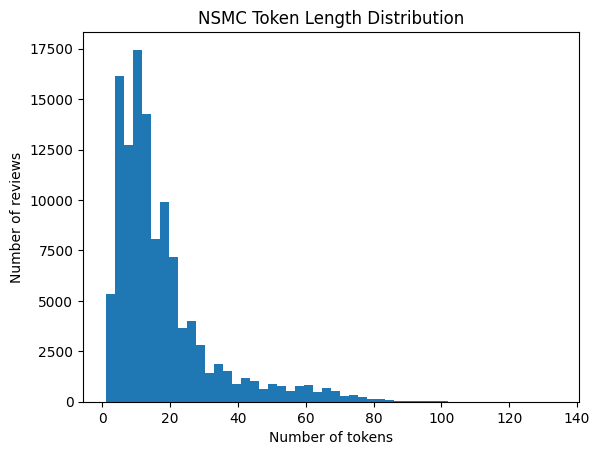

In [94]:

# Analyze encoded review lengths

import numpy as np
import matplotlib.pyplot as plt

train_lengths = [
    len(sp.encode(review, out_type=int))
    for review in train_corpus
]

print("Minimum length:", min(train_lengths))
print("Maximum length:", max(train_lengths))
print("Average length:", np.mean(train_lengths))
print("95th percentile:", np.percentile(train_lengths, 95))

plt.hist(train_lengths, bins=50)
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.title("NSMC Token Length Distribution")
plt.show()


In [95]:

# Encode and pad reviews

import torch

# Choose maximum length using training data only
max_len = min(128, max(1, int(np.ceil(
    np.percentile(train_lengths, 95)
))))

pad_id = sp.pad_id()

def encode_and_pad(texts, max_len):
    encoded = torch.full(
        (len(texts), max_len),
        fill_value=pad_id,
        dtype=torch.long
    )

    for i, text in enumerate(texts):
        token_ids = sp.encode(text, out_type=int)
        token_ids = token_ids[:max_len]

        encoded[i, :len(token_ids)] = torch.tensor(
            token_ids,
            dtype=torch.long
        )

    return encoded

# Convert review text into tensors
X_train = encode_and_pad(
    train_data["document"].tolist(), max_len
)

X_val = encode_and_pad(
    val_data["document"].tolist(), max_len
)

X_test = encode_and_pad(
    test_df["document"].tolist(), max_len
)

# Convert labels into tensors
y_train = torch.tensor(
    train_data["label"].to_numpy(),
    dtype=torch.float32
)

y_val = torch.tensor(
    val_data["label"].to_numpy(),
    dtype=torch.float32
)

y_test = torch.tensor(
    test_df["label"].to_numpy(),
    dtype=torch.float32
)

print("Selected maximum length:", max_len)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


Selected maximum length: 52
X_train: torch.Size([116945, 52])
y_train: torch.Size([116945])
X_val: torch.Size([29237, 52])
X_test: torch.Size([49157, 52])


In [96]:

import torch
from torch.utils.data import TensorDataset, DataLoader

# Create datasets
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Number of reviews processed in one batch
batch_size = 64

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 1828
Validation batches: 457
Test batches: 769


In [97]:

import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

class SentimentGRU(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        pad_id=3
    ):
        super().__init__()

        self.pad_id = pad_id

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_id
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):

        # Find non-padding sequence lengths
        lengths = (x != self.pad_id).sum(dim=1)
        lengths = lengths.clamp(min=1).cpu()

        # Convert token IDs to vectors
        embedded = self.embedding(x)

        # Ignore right-side padding in the GRU
        packed = pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        # Process sequence using GRU
        output, hidden = self.gru(packed)

        # Last hidden state: [batch, hidden_dim]
        last_hidden = hidden[-1]

        # Produce one classification logit
        logits = self.fc(last_hidden).squeeze(1)

        return logits


In [98]:

# Choose GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create our model
model = SentimentGRU(
    vocab_size=sp.get_piece_size(),
    embedding_dim=128,
    hidden_dim=128,
    pad_id=sp.pad_id()
).to(device)

# Binary classification loss
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Device:", device)
print(model)


Device: cuda
SentimentGRU(
  (embedding): Embedding(8000, 128, padding_idx=3)
  (gru): GRU(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [99]:

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(X_batch)

        # Calculate loss
        loss = criterion(logits, y_batch)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        # Update model parameters
        optimizer.step()

        total_loss += loss.item() * y_batch.size(0)

        predictions = (logits >= 0).float()
        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            total_loss += loss.item() * y_batch.size(0)

            predictions = (logits >= 0).float()
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    return total_loss / total, correct / total


In [100]:

# Number of epochs
num_epochs = 5

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_accuracy = -1.0

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # Save the best model
    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        torch.save(
            model.state_dict(),
            "best_sentencepiece_gru.pth"
        )

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

print("Best validation accuracy:", best_val_accuracy)


Epoch 1/5 | Train Loss: 0.4519 | Train Acc: 0.7815 | Val Loss: 0.3662 | Val Acc: 0.8358
Epoch 2/5 | Train Loss: 0.3175 | Train Acc: 0.8619 | Val Loss: 0.3431 | Val Acc: 0.8484
Epoch 3/5 | Train Loss: 0.2654 | Train Acc: 0.8886 | Val Loss: 0.3441 | Val Acc: 0.8520
Epoch 4/5 | Train Loss: 0.2132 | Train Acc: 0.9124 | Val Loss: 0.3723 | Val Acc: 0.8515
Epoch 5/5 | Train Loss: 0.1569 | Train Acc: 0.9393 | Val Loss: 0.4333 | Val Acc: 0.8449
Best validation accuracy: 0.8520025994459076


In [101]:

# Evaluate the best saved model

# Load the best model weights
model.load_state_dict(
    torch.load(
        "best_sentencepiece_gru.pth",
        map_location=device,
        weights_only=True
    )
)

# Evaluate on unseen test reviews
test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Accuracy (%): {test_acc * 100:.2f}%")


Test Loss: 0.3510
Test Accuracy: 0.8482
Test Accuracy (%): 84.82%


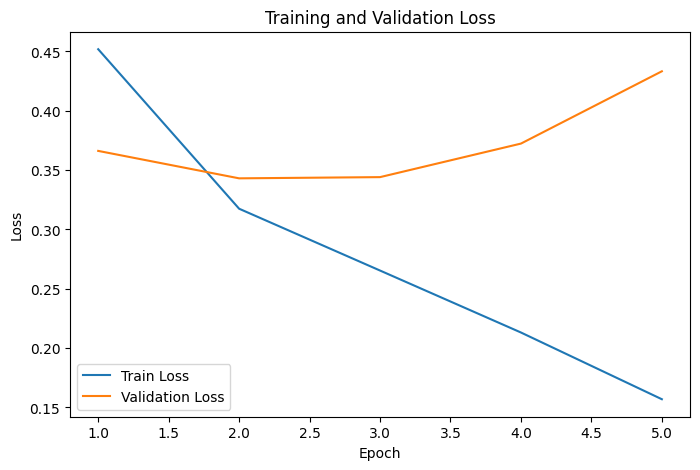

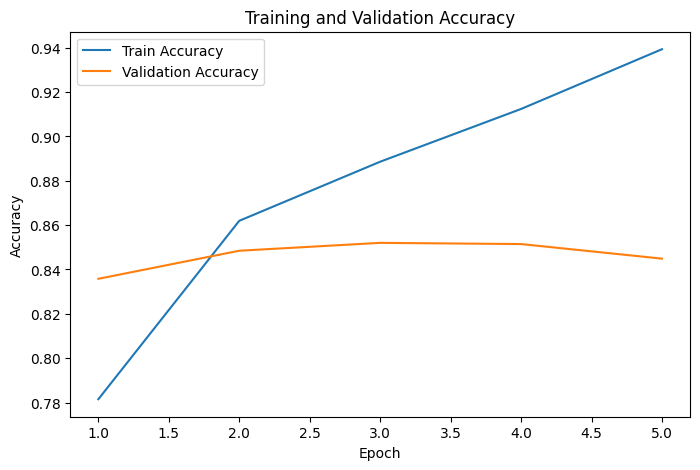

In [102]:

# Visualize training history

import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

# Plot 1: Loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

# Plot 2: Accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()


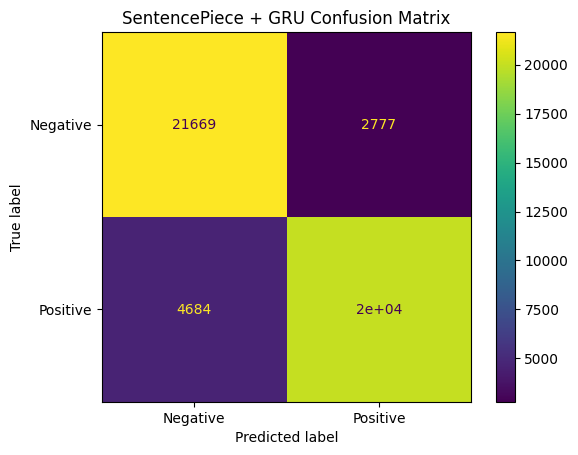

              precision    recall  f1-score   support

    Negative     0.8223    0.8864    0.8531     24446
    Positive     0.8782    0.8104    0.8430     24711

    accuracy                         0.8482     49157
   macro avg     0.8502    0.8484    0.8481     49157
weighted avg     0.8504    0.8482    0.8480     49157



In [103]:

# Confusion matrix and classification report

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        logits = model(X_batch)

        predictions = (logits >= 0).long()

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_labels.extend(
            y_batch.long().tolist()
        )

# Create confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("SentencePiece + GRU Confusion Matrix")
plt.show()

# Print detailed classification metrics
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Negative", "Positive"],
    digits=4
))


In [104]:

# Code 19: Predict sentiment for new Korean reviews

def predict_sentiment(review):

    model.eval()

    # Encode and pad the new review
    encoded = encode_and_pad(
        [review],
        max_len
    ).to(device)

    # Generate prediction
    with torch.no_grad():
        logit = model(encoded)
        probability = torch.sigmoid(logit).item()

    # Convert probability into label
    if probability >= 0.5:
        label = "Positive"
    else:
        label = "Negative"

    return label, probability


# Test examples
reviews = [
    "정말 재미있고 감동적인 영화였습니다.",
    "너무 지루하고 시간 낭비였어요.",
    "배우들의 연기는 좋았지만 스토리는 별로였어요."
]

for review in reviews:
    label, probability = predict_sentiment(review)

    print("Review:", review)
    print("Prediction:", label)
    print(f"Positive probability: {probability:.4f}")
    print("-" * 50)


Review: 정말 재미있고 감동적인 영화였습니다.
Prediction: Positive
Positive probability: 0.9988
--------------------------------------------------
Review: 너무 지루하고 시간 낭비였어요.
Prediction: Negative
Positive probability: 0.0003
--------------------------------------------------
Review: 배우들의 연기는 좋았지만 스토리는 별로였어요.
Prediction: Negative
Positive probability: 0.0219
--------------------------------------------------


#Comparing SentencePiece with other other tokenizers

In [105]:

from konlpy.tag import Mecab, Okt

mecab = Mecab()
okt = Okt()

sentence = "이 영화는 정말 재미있고 감동적이에요!"

print("MeCab:", mecab.morphs(sentence))
print("Okt:", okt.morphs(sentence))



MeCab: ['이', '영화', '는', '정말', '재미있', '고', '감동', '적', '이', '에요', '!']
Okt: ['이', '영화', '는', '정말', '재미있고', '감동', '적', '이에요', '!']


In [106]:

# Prepare the same dataset splits
train_texts = train_data["document"].tolist()
val_texts = val_data["document"].tolist()
test_texts = test_df["document"].tolist()

def tokenize_reviews(texts, analyzer):
    return [
        analyzer.morphs(text)
        for text in texts
    ]

# MeCab
mecab_train = tokenize_reviews(train_texts, mecab)
mecab_val = tokenize_reviews(val_texts, mecab)
mecab_test = tokenize_reviews(test_texts, mecab)

# Okt
okt_train = tokenize_reviews(train_texts, okt)
okt_val = tokenize_reviews(val_texts, okt)
okt_test = tokenize_reviews(test_texts, okt)

print("MeCab example:", mecab_train[0])
print("Okt example:", okt_train[0])


MeCab example: ['허니', '잼', '예스', '잼', '꿀', '잼', '잼', '잼']
Okt example: ['허니', '잼', '예스', '잼', '꿀잼', '잼잼']


In [107]:

from collections import Counter
import torch

def prepare_konlpy_data(
    train_tokens, val_tokens, test_tokens, max_len
):
    # Count token frequencies from training data only
    counts = Counter(
        token
        for sentence in train_tokens
        for token in sentence
    )

    # Reserve 0 for padding and 1 for unknown tokens
    word_index = {"<pad>": 0, "<unk>": 1}

    for word in counts:
        word_index[word] = len(word_index)

    # Convert token lists into padded tensors
    def encode(tokenized_texts):
        X = torch.zeros(
            (len(tokenized_texts), max_len),
            dtype=torch.long
        )

        for i, sentence in enumerate(tokenized_texts):
            ids = [
                word_index.get(token, 1)
                for token in sentence[:max_len]
            ]

            X[i, :len(ids)] = torch.tensor(
                ids, dtype=torch.long
            )

        return X

    X_train = encode(train_tokens)
    X_val = encode(val_tokens)
    X_test = encode(test_tokens)

    return X_train, X_val, X_test, word_index


In [109]:

tokenizer_datasets = {}

for name, train_tok, val_tok, test_tok in [
    ("MeCab", mecab_train, mecab_val, mecab_test),
    ("Okt", okt_train, okt_val, okt_test)
]:
    X_tr, X_va, X_te, vocab = prepare_konlpy_data(
        train_tok,
        val_tok,
        test_tok,
        max_len
    )

    tokenizer_datasets[name] = {
        "X_train": X_tr,
        "X_val": X_va,
        "X_test": X_te,
        "vocab_size": len(vocab),
        "pad_id": 0
    }

    print(name, "vocabulary size:", len(vocab))


MeCab vocabulary size: 48835
Okt vocabulary size: 92689


In [110]:

from torch.utils.data import TensorDataset, DataLoader
import pandas as pd

results = []

# Include our earlier SentencePiece result
results.append({
    "Tokenizer": "SentencePiece",
    "Vocab Size": sp.get_piece_size(),
    "Validation Accuracy": best_val_accuracy
})

for name, data in tokenizer_datasets.items():

    print(f"\nTraining {name} model...")

    # Create DataLoaders
    train_dl = DataLoader(
        TensorDataset(data["X_train"], y_train),
        batch_size=64,
        shuffle=True
    )

    val_dl = DataLoader(
        TensorDataset(data["X_val"], y_val),
        batch_size=64,
        shuffle=False
    )

    # Create a fresh model
    model_k = SentimentGRU(
        vocab_size=data["vocab_size"],
        embedding_dim=128,
        hidden_dim=128,
        pad_id=data["pad_id"]
    ).to(device)

    optimizer_k = torch.optim.Adam(
        model_k.parameters(),
        lr=0.001
    )

    best_acc = 0.0

    # Same number of epochs as SentencePiece
    for epoch in range(5):

        train_loss, train_acc = train_one_epoch(
            model_k, train_dl, optimizer_k, criterion
        )

        val_loss, val_acc = evaluate(
            model_k, val_dl, criterion
        )

        best_acc = max(best_acc, val_acc)

        print(
            f"{name} Epoch {epoch+1}: "
            f"Val Accuracy = {val_acc:.4f}"
        )

    results.append({
        "Tokenizer": name,
        "Vocab Size": data["vocab_size"],
        "Validation Accuracy": best_acc
    })

# Display comparison
results_df = pd.DataFrame(results)
print(results_df)



Training MeCab model...
MeCab Epoch 1: Val Accuracy = 0.8435
MeCab Epoch 2: Val Accuracy = 0.8598
MeCab Epoch 3: Val Accuracy = 0.8610
MeCab Epoch 4: Val Accuracy = 0.8607
MeCab Epoch 5: Val Accuracy = 0.8571

Training Okt model...
Okt Epoch 1: Val Accuracy = 0.8337
Okt Epoch 2: Val Accuracy = 0.8496
Okt Epoch 3: Val Accuracy = 0.8525
Okt Epoch 4: Val Accuracy = 0.8484
Okt Epoch 5: Val Accuracy = 0.8464
       Tokenizer  Vocab Size  Validation Accuracy
0  SentencePiece        8000             0.852003
1          MeCab       48835             0.860998
2            Okt       92689             0.852550


#changing SentencePiece's model_type and vocab_size

In [111]:

import sentencepiece as spm

# New experimental configurations
sp_configs = [
    {"name": "BPE_8000", "model_type": "bpe", "vocab_size": 8000},
    {"name": "Unigram_16000", "model_type": "unigram", "vocab_size": 16000}
]

# Train new tokenizers
for config in sp_configs:

    print("Training:", config["name"])

    spm.SentencePieceTrainer.Train(
        input=corpus_file,
        model_prefix=config["name"],
        vocab_size=config["vocab_size"],
        model_type=config["model_type"],
        pad_id=3
    )

    print("Completed:", config["name"])


Training: BPE_8000
Completed: BPE_8000
Training: Unigram_16000
Completed: Unigram_16000


In [112]:

import torch

def encode_with_sp(processor, texts, max_len):

    pad_id = processor.pad_id()

    X = torch.full(
        (len(texts), max_len),
        pad_id,
        dtype=torch.long
    )

    for i, text in enumerate(texts):

        ids = processor.encode(
            text,
            out_type=int
        )[:max_len]

        X[i, :len(ids)] = torch.tensor(
            ids, dtype=torch.long
        )

    return X


sp_datasets = {}

for config in sp_configs:

    name = config["name"]

    # Load tokenizer
    processor = spm.SentencePieceProcessor()
    processor.load(name + ".model")

    # Encode the same dataset splits
    X_tr = encode_with_sp(
        processor, train_texts, max_len
    )

    X_va = encode_with_sp(
        processor, val_texts, max_len
    )

    sp_datasets[name] = {
        "X_train": X_tr,
        "X_val": X_va,
        "vocab_size": processor.get_piece_size(),
        "pad_id": processor.pad_id()
    }

    print(name, "completed")
    print("Vocabulary:", processor.get_piece_size())
    print("Train shape:", X_tr.shape)


BPE_8000 completed
Vocabulary: 8000
Train shape: torch.Size([116945, 52])
Unigram_16000 completed
Vocabulary: 16000
Train shape: torch.Size([116945, 52])


In [113]:

from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

sp_results = []

# Add original baseline result
sp_results.append({
    "Tokenizer": "Unigram_8000",
    "Vocab Size": sp.get_piece_size(),
    "Validation Accuracy": best_val_accuracy
})

for name, data in sp_datasets.items():

    print("\nTraining:", name)

    # DataLoaders
    train_dl = DataLoader(
        TensorDataset(data["X_train"], y_train),
        batch_size=64,
        shuffle=True
    )

    val_dl = DataLoader(
        TensorDataset(data["X_val"], y_val),
        batch_size=64,
        shuffle=False
    )

    # Reproducible model initialization
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    # Fresh GRU model
    model_sp = SentimentGRU(
        vocab_size=data["vocab_size"],
        embedding_dim=128,
        hidden_dim=128,
        pad_id=data["pad_id"]
    ).to(device)

    optimizer_sp = torch.optim.Adam(
        model_sp.parameters(),
        lr=0.001
    )

    best_acc = -1.0

    for epoch in range(5):

        train_loss, train_acc = train_one_epoch(
            model_sp, train_dl, optimizer_sp, criterion
        )

        val_loss, val_acc = evaluate(
            model_sp, val_dl, criterion
        )

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(
                model_sp.state_dict(),
                f"best_{name}.pth"
            )

        print(
            f"Epoch {epoch+1}/5 | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    sp_results.append({
        "Tokenizer": name,
        "Vocab Size": data["vocab_size"],
        "Validation Accuracy": best_acc
    })



Training: BPE_8000
Epoch 1/5 | Train Acc: 0.7845 | Val Acc: 0.8391
Epoch 2/5 | Train Acc: 0.8622 | Val Acc: 0.8525
Epoch 3/5 | Train Acc: 0.8880 | Val Acc: 0.8513
Epoch 4/5 | Train Acc: 0.9139 | Val Acc: 0.8477
Epoch 5/5 | Train Acc: 0.9419 | Val Acc: 0.8465

Training: Unigram_16000
Epoch 1/5 | Train Acc: 0.7706 | Val Acc: 0.8312
Epoch 2/5 | Train Acc: 0.8659 | Val Acc: 0.8474
Epoch 3/5 | Train Acc: 0.8993 | Val Acc: 0.8484
Epoch 4/5 | Train Acc: 0.9290 | Val Acc: 0.8438
Epoch 5/5 | Train Acc: 0.9577 | Val Acc: 0.8422


In [114]:

import pandas as pd

# SentencePiece configuration results
sp_results_df = pd.DataFrame(sp_results)

sp_results_df["Validation Accuracy (%)"] = (
    sp_results_df["Validation Accuracy"] * 100
)

sp_results_df = sp_results_df.sort_values(
    "Validation Accuracy",
    ascending=False
)

print("SentencePiece Comparison")
display(sp_results_df)

# Combine with previous KoNLPy results, if available
if "results_df" in globals():
    print("\nSentencePiece vs KoNLPy")
    display(results_df)


SentencePiece Comparison


,Tokenizer,Vocab Size,Validation Accuracy,Validation Accuracy (%)
1,BPE_8000,8000,0.852516,85.251565
0,Unigram_8000,8000,0.852003,85.200260
2,Unigram_16000,16000,0.848445,84.844546



SentencePiece vs KoNLPy


,Tokenizer,Vocab Size,Validation Accuracy
0,SentencePiece,8000,0.852003
1,MeCab,48835,0.860998
2,Okt,92689,0.852550


In [115]:

# Select the best configuration
best_name = sp_results_df.iloc[0]["Tokenizer"]

# Locate its tokenizer and saved model
if best_name == "Unigram_8000":
    best_processor = sp
    best_weights = "best_sentencepiece_gru.pth"
else:
    best_processor = spm.SentencePieceProcessor()
    best_processor.load(best_name + ".model")
    best_weights = f"best_{best_name}.pth"

# Encode test reviews
X_final_test = encode_with_sp(
    best_processor, test_texts, max_len
)

final_test_loader = DataLoader(
    TensorDataset(X_final_test, y_test),
    batch_size=64,
    shuffle=False
)

# Restore the selected GRU model
final_model = SentimentGRU(
    vocab_size=best_processor.get_piece_size(),
    embedding_dim=128,
    hidden_dim=128,
    pad_id=best_processor.pad_id()
).to(device)

final_model.load_state_dict(
    torch.load(
        best_weights,
        map_location=device,
        weights_only=True
    )
)

# Final test evaluation
test_loss, test_acc = evaluate(
    final_model, final_test_loader, criterion
)

print("Best SentencePiece:", best_name)
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")


Best SentencePiece: BPE_8000
Final Test Accuracy: 84.97%
